# LSTM vs BiLSTM Attention Comparison — AG News (Colab CPU)

Self-contained Colab notebook. Upload `train.csv` and `test.csv` to `/content/` then run all cells.

Trains all 8 models (4 LSTM + 4 BiLSTM variants) on the **full** AG News train.csv (120k samples)
with identical settings for a fair architecture comparison.

Hyperparameters:
- Vocab size: 20,000 | Max length: 48 | Embedding dim: 100
- LSTM hidden (per dir): 64 | Layers: 1 | Attention dim: 32
- Dropout: 0.3 | Adam lr: 1e-3 | Weight decay: 1e-5
- Batch size: 64 | Max epochs: 8 | Early stop patience: 2 | Grad clip: 1.0
- Val split: 10% (stratified, seed 2025) | Seeds: 13, 42
- Scheduler: ReduceLROnPlateau, factor=0.5, patience=1

Models:
1. lstm_baseline | 2. lstm_additive | 3. lstm_multiplicative | 4. lstm_self_attention
5. bilstm_baseline | 6. bilstm_additive | 7. bilstm_multiplicative | 8. bilstm_self_attention

Results are saved incrementally to Google Drive. A Colab disconnect only costs the current run.
Results go to: `MyDrive/agnews_lstm_experiments/`


In [ ]:
!pip install -q scikit-learn pandas numpy torch


In [ ]:
import os, re, json, time, random, math, hashlib, platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)
from IPython.display import display

print('Python:', platform.python_version())
print('PyTorch:', torch.__version__)
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)

DEVICE = torch.device('cpu')  # Experiments are intentionally CPU-only
print('Device:', DEVICE)


In [ ]:
USE_GOOGLE_DRIVE = True
DEBUG_RUN = False  # Set to False to run the full experiment

TRAIN_CSV = '/content/train.csv'
TEST_CSV = '/content/test.csv'
MAX_VOCAB = 20_000
MAX_LEN = 48
EMBED_DIM = 100
HIDDEN_DIM = 64
ATTENTION_DIM = 32
DROPOUT = 0.3
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 8
EARLY_STOPPING_PATIENCE = 2
GRADIENT_CLIP = 1.0
SEEDS = [13, 42]
SPLIT_SEED = 2025
SAMPLE_SIZE = -1  # -1 means use the entire official train.csv

MODEL_NAMES = [
    'lstm_baseline', 'lstm_additive', 'lstm_multiplicative', 'lstm_self_attention',
    'bilstm_baseline', 'bilstm_additive', 'bilstm_multiplicative', 'bilstm_self_attention'
]
CLASS_NAMES = ['World', 'Sports', 'Business', 'Sci/Tech']

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        print('Mounting Google Drive...')
        drive.mount('/content/drive')
        OUTPUT_DIR = Path('/content/drive/MyDrive/agnews_lstm_experiments')
    except Exception as e:
        print(f'Google Drive mount failed ({type(e).__name__}: {e}). Falling back to local storage.')
        OUTPUT_DIR = Path('./agnews_lstm_experiments')
else:
    OUTPUT_DIR = Path('./agnews_lstm_experiments')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_JSONL = OUTPUT_DIR / 'results.jsonl'
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
CACHE_DIR = OUTPUT_DIR / 'cache'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE, '| Output:', OUTPUT_DIR.resolve())


In [ ]:
def ensure_csv_files():
    missing = [p for p in [TRAIN_CSV, TEST_CSV] if not Path(p).exists()]
    if missing:
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError(f'Missing CSV file(s): {missing}. Set TRAIN_CSV/TEST_CSV to valid paths.') from exc
        uploaded = files.upload()
        for name in uploaded:
            source = Path(name)
            if source.name == 'train.csv':
                if source.resolve() != Path(TRAIN_CSV).resolve():
                    source.replace(TRAIN_CSV)
            elif source.name == 'test.csv':
                if source.resolve() != Path(TEST_CSV).resolve():
                    source.replace(TEST_CSV)
        still_missing = [p for p in [TRAIN_CSV, TEST_CSV] if not Path(p).exists()]
        if still_missing:
            raise FileNotFoundError(f'Upload train.csv and test.csv; still missing: {still_missing}')

ensure_csv_files()


In [ ]:
def read_ag_news(path):
    try:
        frame = pd.read_csv(path)
    except pd.errors.ParserError:
        print(f'Warning: standard CSV parser failed on {path}. Trying python engine with bad-line skipping...')
        frame = pd.read_csv(path, engine='python', on_bad_lines='skip')

    required = {'Class Index', 'Title', 'Description'}
    absent = required.difference(frame.columns)
    if absent:
        raise ValueError(f'{path} is missing required columns: {sorted(absent)}; found {list(frame.columns)}')
    frame = frame[['Class Index', 'Title', 'Description']].copy()
    if frame.isna().any().any():
        frame[['Title', 'Description']] = frame[['Title', 'Description']].fillna('')
    labels = pd.to_numeric(frame['Class Index'], errors='raise').astype(int)
    if not labels.isin([1, 2, 3, 4]).all():
        raise ValueError('Class Index labels must be the official AG News values 1 through 4.')
    texts = (frame['Title'].astype(str) + ' ' + frame['Description'].astype(str)).tolist()
    return texts, labels.to_numpy(dtype=np.int64) - 1

all_train_texts, all_train_y = read_ag_news(TRAIN_CSV)
test_texts, test_y = read_ag_news(TEST_CSV)
print(f'Official train rows: {len(all_train_y):,}; official test rows: {len(test_y):,}')
print('Train class counts:', dict(zip(*np.unique(all_train_y, return_counts=True))))
print('Test class counts:', dict(zip(*np.unique(test_y, return_counts=True))))
assert len(test_y) == len(test_texts)


In [ ]:
TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?")
PAD_ID, UNK_ID = 0, 1

def tokenize(text):
    return TOKEN_RE.findall(text.lower())

def prepare_data(sample_size):
    if sample_size is None or sample_size == -1:
        n = len(all_train_y)
    else:
        n = min(int(sample_size), len(all_train_y))
    if n < len(all_train_y):
        selected, _ = train_test_split(
            np.arange(len(all_train_y)), train_size=n, random_state=SPLIT_SEED,
            stratify=all_train_y
        )
    else:
        selected = np.arange(len(all_train_y))
    sampled_texts = [all_train_texts[i] for i in selected]
    sampled_y = all_train_y[selected]
    tr_idx, va_idx = train_test_split(
        np.arange(n), test_size=0.10, random_state=SPLIT_SEED,
        stratify=sampled_y
    )
    tokenized_train = [tokenize(sampled_texts[i]) for i in tr_idx]
    counts = Counter(token for row in tokenized_train for token in row)
    vocab = {'<PAD>': PAD_ID, '<UNK>': UNK_ID}
    for token, _ in counts.most_common(MAX_VOCAB - len(vocab)):
        vocab[token] = len(vocab)

    def encode(rows):
        ids = np.zeros((len(rows), MAX_LEN), dtype=np.int64)
        lengths = np.zeros(len(rows), dtype=np.int64)
        for i, text in enumerate(rows):
            pieces = tokenize(text)[:MAX_LEN]
            encoded = [vocab.get(piece, UNK_ID) for piece in pieces]
            lengths[i] = max(1, len(encoded))
            if not encoded:
                encoded = [UNK_ID]
            ids[i, :len(encoded)] = encoded
        return torch.from_numpy(ids), torch.from_numpy(lengths)

    x_train, len_train = encode([sampled_texts[i] for i in tr_idx])
    x_val, len_val = encode([sampled_texts[i] for i in va_idx])
    x_test, len_test = encode(test_texts)
    return {
        'x_train': x_train, 'len_train': len_train, 'y_train': torch.tensor(sampled_y[tr_idx]),
        'x_val': x_val, 'len_val': len_val, 'y_val': torch.tensor(sampled_y[va_idx]),
        'x_test': x_test, 'len_test': len_test, 'y_test': torch.tensor(test_y),
        'vocab': vocab, 'sampled_train_rows': n
    }

cache_sources = []
for filename in [TRAIN_CSV, TEST_CSV]:
    stat = Path(filename).stat()
    cache_sources.append((str(Path(filename).resolve()), stat.st_size, stat.st_mtime_ns))
cache_spec = {'sources': cache_sources, 'sample_size': SAMPLE_SIZE, 'max_vocab': MAX_VOCAB,
              'max_len': MAX_LEN, 'split_seed': SPLIT_SEED, 'tokenizer': 'lowercase-regex-v1'}
cache_id = hashlib.sha256(json.dumps(cache_spec, sort_keys=True).encode()).hexdigest()[:16]
CACHE_PATH = CACHE_DIR / f'encoded_agnews_{cache_id}.pt'
if CACHE_PATH.exists():
    data = torch.load(CACHE_PATH, map_location='cpu', weights_only=False)
    print('Loaded pre-tokenized tensor cache:', CACHE_PATH)
else:
    data = prepare_data(SAMPLE_SIZE)
    torch.save(data, CACHE_PATH)
    with (CACHE_DIR / f'vocab_{cache_id}.json').open('w', encoding='utf-8') as f:
        json.dump(data['vocab'], f)
    print('Created pre-tokenized tensor cache:', CACHE_PATH)

lengths_all = [len(tokenize(t)) for t in all_train_texts]
p95 = float(np.percentile(lengths_all, 95))
print(f'95th percentile tokenized length (full train): {p95:.1f}; configured max length: {MAX_LEN}')
print(f'Sampled official training rows: {data["sampled_train_rows"]:,}; train/val: {len(data["y_train"]):,}/{len(data["y_val"]):,}')
print(f'Vocabulary size: {len(data["vocab"]):,}; tensors: train {tuple(data["x_train"].shape)}, test {tuple(data["x_test"].shape)}')
if p95 > MAX_LEN:
    print('Note: the fixed plan length of 48 is below the full-data 95th percentile; inputs are truncated at 48 for every model.')


In [ ]:
class LSTMTextClassifier(nn.Module):
    def __init__(self, variant, vocab_size):
        super().__init__()
        if variant not in MODEL_NAMES:
            raise ValueError(f'Unknown variant: {variant}')
        self.variant = variant
        self.bidirectional = variant.startswith('bilstm_')
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=PAD_ID)
        self.embedding_dropout = nn.Dropout(DROPOUT)
        lstm_output_dim = HIDDEN_DIM * 2 if self.bidirectional else HIDDEN_DIM
        self.lstm_output_dim = lstm_output_dim
        self.lstm = nn.LSTM(
            EMBED_DIM, HIDDEN_DIM, num_layers=1,
            bidirectional=self.bidirectional, batch_first=True)
        self.classifier_dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(lstm_output_dim, 4)
        if variant in ('lstm_additive', 'bilstm_additive'):
            self.additive_hidden = nn.Linear(lstm_output_dim, ATTENTION_DIM, bias=False)
            self.additive_query = nn.Parameter(torch.empty(ATTENTION_DIM))
            self.additive_score = nn.Linear(ATTENTION_DIM, 1, bias=False)
            nn.init.normal_(self.additive_query, std=0.1)
        elif variant in ('lstm_multiplicative', 'bilstm_multiplicative'):
            self.bilinear = nn.Linear(lstm_output_dim, lstm_output_dim, bias=False)
            self.context_query = nn.Parameter(torch.empty(lstm_output_dim))
            nn.init.normal_(self.context_query, std=0.1)
        elif variant in ('lstm_self_attention', 'bilstm_self_attention'):
            self.query = nn.Linear(lstm_output_dim, lstm_output_dim, bias=False)
            self.key = nn.Linear(lstm_output_dim, lstm_output_dim, bias=False)
            self.value = nn.Linear(lstm_output_dim, lstm_output_dim, bias=False)

    @staticmethod
    def masked_softmax(scores, mask):
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
        return torch.softmax(scores, dim=-1)

    def forward(self, token_ids, lengths, return_attention=False):
        mask = token_ids.ne(PAD_ID)
        embedded = self.embedding_dropout(self.embedding(token_ids))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, (hidden, _) = self.lstm(packed)
        outputs, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=token_ids.size(1))
        attention_weights = None
        if self.variant in ('lstm_baseline', 'bilstm_baseline'):
            if self.bidirectional:
                sentence = torch.cat([hidden[-2], hidden[-1]], dim=1)
            else:
                sentence = hidden[-1]
        elif self.variant in ('lstm_additive', 'bilstm_additive'):
            scores = self.additive_score(torch.tanh(self.additive_hidden(outputs) + self.additive_query)).squeeze(-1)
            weights = self.masked_softmax(scores, mask)
            sentence = torch.sum(outputs * weights.unsqueeze(-1), dim=1)
        elif self.variant in ('lstm_multiplicative', 'bilstm_multiplicative'):
            query = self.context_query.expand(outputs.size(0), -1)
            scores = torch.bmm(self.bilinear(outputs), query.unsqueeze(-1)).squeeze(-1)
            weights = self.masked_softmax(scores, mask)
            sentence = torch.sum(outputs * weights.unsqueeze(-1), dim=1)
        else:
            q, k, v = self.query(outputs), self.key(outputs), self.value(outputs)
            scores = torch.bmm(q, k.transpose(1, 2)) / math.sqrt(self.lstm_output_dim)
            key_mask = mask.unsqueeze(1).expand_as(scores)
            weights = self.masked_softmax(scores, key_mask)
            contextual = torch.bmm(weights, v)
            contextual = contextual * mask.unsqueeze(-1)
            sentence = contextual.sum(dim=1) / lengths.to(contextual.dtype).unsqueeze(1).clamp_min(1)
        logits = self.classifier(self.classifier_dropout(sentence))
        if return_attention:
            return logits, attention_weights
        return logits

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for name in MODEL_NAMES:
    model = LSTMTextClassifier(name, len(data['vocab']))
    print(f'{name:24s} {count_parameters(model):,} trainable parameters')
    del model


In [ ]:
class TensorTextDataset(Dataset):
    def __init__(self, x, lengths, y):
        self.x, self.lengths, self.y = x, lengths, y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.x[idx], self.lengths[idx], self.y[idx]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def make_loader(x, lengths, y, shuffle):
    generator = torch.Generator().manual_seed(1234) if shuffle else None
    return DataLoader(TensorTextDataset(x, lengths, y), batch_size=BATCH_SIZE,
                      shuffle=shuffle, generator=generator, num_workers=0)

@torch.no_grad()
def evaluate_loss(model, loader, criterion):
    model.eval()
    total_loss, count, correct = 0.0, 0, 0
    for x, lengths, y in loader:
        logits = model(x.to(DEVICE), lengths)
        y = y.to(DEVICE)
        total_loss += criterion(logits, y).item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        count += y.size(0)
    return total_loss / count, correct / count

@torch.no_grad()
def predict(model, loader):
    model.eval()
    predictions = []
    for x, lengths, _ in loader:
        predictions.extend(model(x.to(DEVICE), lengths).argmax(1).cpu().tolist())
    return np.asarray(predictions, dtype=np.int64)

def train_one(model_name, seed, train_data, val_data, epochs, save_checkpoint=True, vocab_size=None):
    set_seed(seed)
    model = LSTMTextClassifier(model_name, vocab_size or len(data['vocab'])).to(DEVICE)
    train_loader = make_loader(*train_data, shuffle=True)
    val_loader = make_loader(*val_data, shuffle=False)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)
    best_val_loss, best_state, stale, history = float('inf'), None, 0, []
    start_total = time.perf_counter()
    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        model.train()
        total_loss, count, correct = 0.0, 0, 0
        for x, lengths, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x, lengths)
            loss = criterion(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP)
            optimizer.step()
            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            count += y.size(0)
        train_loss, train_acc = total_loss / count, correct / count
        val_loss, val_acc = evaluate_loss(model, val_loader, criterion)
        scheduler.step(val_loss)
        epoch_seconds = time.perf_counter() - epoch_start
        row = {'epoch': epoch, 'train_loss': train_loss, 'train_accuracy': train_acc,
               'val_loss': val_loss, 'val_accuracy': val_acc, 'epoch_seconds': epoch_seconds,
               'learning_rate': optimizer.param_groups[0]['lr']}
        history.append(row)
        print(f'{model_name} seed={seed} epoch={epoch}/{epochs} '
              f'train_loss={train_loss:.4f} train_acc={train_acc:.4f} '
              f'val_loss={val_loss:.4f} val_acc={val_acc:.4f} time={epoch_seconds:.1f}s')
        if val_loss < best_val_loss:
            best_val_loss, best_state, stale = val_loss, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            stale += 1
        if stale >= EARLY_STOPPING_PATIENCE:
            print(f'Early stopping after epoch {epoch}.')
            break
    if best_state is None:
        raise RuntimeError('Training did not produce a valid checkpoint.')
    model.load_state_dict(best_state)
    elapsed = time.perf_counter() - start_total
    checkpoint_path = CHECKPOINT_DIR / f'{model_name}_seed{seed}.pt'
    if save_checkpoint:
        torch.save({'model_name': model_name, 'seed': seed, 'state_dict': best_state,
                    'vocab_size': len(data['vocab']), 'max_len': MAX_LEN}, checkpoint_path)
    return model, history, elapsed, checkpoint_path

def inference_latency_ms(model, loader, warmup_batches=5, timed_batches=30):
    model.eval()
    batches = list(loader)
    if not batches:
        raise ValueError('Cannot benchmark inference on an empty loader.')
    for i in range(min(warmup_batches, len(batches))):
        x, lengths, _ = batches[i]
        model(x.to(DEVICE), lengths)
    elapsed, examples = 0.0, 0
    with torch.no_grad():
        for i in range(min(timed_batches, len(batches))):
            x, lengths, _ = batches[i]
            start = time.perf_counter()
            model(x.to(DEVICE), lengths)
            elapsed += time.perf_counter() - start
            examples += len(x)
    return elapsed * 1000 / examples  # milliseconds per example


In [9]:
def completed_runs(path, experiment_id):
    done = set()
    if path.exists():
        with path.open('r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    row = json.loads(line)
                    if row.get('run_type') == 'full' and row.get('experiment_id') == experiment_id:
                        done.add((row['model'], int(row['seed'])))
    return done

if DEBUG_RUN:
    print('Debug mode skipped: set DEBUG_RUN = False to run the full experiment.')
else:
    train_tuple = (data['x_train'], data['len_train'], data['y_train'])
    val_tuple = (data['x_val'], data['len_val'], data['y_val'])
    test_loader = make_loader(data['x_test'], data['len_test'], data['y_test'], shuffle=False)
    done = completed_runs(RESULTS_JSONL, cache_id)
    for model_name in MODEL_NAMES:
        for seed in SEEDS:
            if (model_name, seed) in done:
                print(f'Skipping completed full run: {model_name}, seed={seed}')
                continue
            model, history, total_seconds, checkpoint_path = train_one(
                model_name, seed, train_tuple, val_tuple, MAX_EPOCHS, save_checkpoint=True)
            y_pred = predict(model, test_loader)
            y_true = data['y_test'].numpy()
            report = classification_report(y_true, y_pred, labels=[0, 1, 2, 3],
                                           target_names=CLASS_NAMES, output_dict=True, zero_division=0)
            latency = inference_latency_ms(model, test_loader)
            record = {
                'run_type': 'full', 'experiment_id': cache_id, 'model': model_name, 'seed': seed,
                'sampled_official_train_rows': data['sampled_train_rows'],
                'train_rows': len(data['y_train']), 'validation_rows': len(data['y_val']),
                'test_rows': len(y_true), 'vocab_size': len(data['vocab']),
                'max_sequence_length': MAX_LEN, 'parameter_count': count_parameters(model),
                'test_accuracy': accuracy_score(y_true, y_pred),
                'test_macro_f1': f1_score(y_true, y_pred, average='macro'),
                'best_validation_loss': min(history, key=lambda item: item['val_loss'])['val_loss'],
                'validation_accuracy_at_best_loss': min(history, key=lambda item: item['val_loss'])['val_accuracy'],
                'per_class_precision_recall': {name: {'precision': report[name]['precision'],
                    'recall': report[name]['recall'], 'f1': report[name]['f1-score']}
                    for name in CLASS_NAMES},
                'inference_ms_per_example': latency,
                'total_training_seconds': total_seconds, 'epoch_history': history,
                'checkpoint': str(checkpoint_path), 'test_predictions': y_pred.tolist(),
                'hyperparameters': {'embedding_dim': EMBED_DIM, 'hidden_dim': HIDDEN_DIM,
                    'attention_dim': ATTENTION_DIM, 'dropout': DROPOUT, 'batch_size': BATCH_SIZE,
                    'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY,
                    'max_epochs': MAX_EPOCHS, 'early_stopping_patience': EARLY_STOPPING_PATIENCE,
                    'gradient_clip': GRADIENT_CLIP, 'optimizer': 'Adam',
                    'scheduler': 'ReduceLROnPlateau', 'device': str(DEVICE),
                    'torch_version': torch.__version__, 'numpy_version': np.__version__,
                    'pandas_version': pd.__version__}
            }
            with RESULTS_JSONL.open('a', encoding='utf-8') as f:
                f.write(json.dumps(record) + '\n')
            print(f"Saved: {model_name} seed={seed} | test accuracy={record['test_accuracy']:.4f} "
                  f"macro-F1={record['test_macro_f1']:.4f} | inference={latency:.3f} ms/example")
            del model
    print('Full experiment loop finished. Results:', RESULTS_JSONL)


lstm_baseline seed=13 epoch=1/8 train_loss=0.7025 train_acc=0.7152 val_loss=0.3973 val_acc=0.8737 time=171.6s
lstm_baseline seed=13 epoch=2/8 train_loss=0.3495 train_acc=0.8849 val_loss=0.3136 val_acc=0.8960 time=169.3s
lstm_baseline seed=13 epoch=3/8 train_loss=0.2823 train_acc=0.9087 val_loss=0.2830 val_acc=0.9081 time=162.6s
lstm_baseline seed=13 epoch=4/8 train_loss=0.2462 train_acc=0.9210 val_loss=0.2701 val_acc=0.9108 time=170.8s
lstm_baseline seed=13 epoch=5/8 train_loss=0.2200 train_acc=0.9295 val_loss=0.2688 val_acc=0.9129 time=162.8s
lstm_baseline seed=13 epoch=6/8 train_loss=0.1967 train_acc=0.9357 val_loss=0.2670 val_acc=0.9122 time=168.9s
lstm_baseline seed=13 epoch=7/8 train_loss=0.1804 train_acc=0.9397 val_loss=0.2720 val_acc=0.9107 time=162.6s
lstm_baseline seed=13 epoch=8/8 train_loss=0.1613 train_acc=0.9456 val_loss=0.2748 val_acc=0.9131 time=162.1s
Early stopping after epoch 8.
Saved: lstm_baseline seed=13 | test accuracy=0.9166 macro-F1=0.9164 | inference=0.160 ms/e

In [10]:
def load_full_results(path, experiment_id):
    if not path.exists():
        raise FileNotFoundError(f'No results at {path}. Run the full experiment first.')
    with path.open('r', encoding='utf-8') as f:
        rows = [json.loads(line) for line in f if line.strip()]
    return [r for r in rows if r.get('run_type') == 'full' and r.get('experiment_id') == experiment_id]

full_rows = load_full_results(RESULTS_JSONL, cache_id) if RESULTS_JSONL.exists() else []
if full_rows:
    summary = pd.DataFrame(full_rows).groupby('model').agg(
        seeds=('seed', 'count'), accuracy_mean=('test_accuracy', 'mean'),
        accuracy_std=('test_accuracy', 'std'), macro_f1_mean=('test_macro_f1', 'mean'),
        macro_f1_std=('test_macro_f1', 'std'), parameters=('parameter_count', 'mean'),
        best_validation_loss_mean=('best_validation_loss', 'mean'),
        train_seconds_mean=('total_training_seconds', 'mean'),
        inference_ms_per_example_mean=('inference_ms_per_example', 'mean')).reset_index()
    display(summary)
    summary.to_csv(OUTPUT_DIR / 'summary.csv', index=False)
    print('Saved summary:', OUTPUT_DIR / 'summary.csv')
else:
    print('No full results available yet. Run the experiment cell above first.')


,model,seeds,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,best_validation_loss_mean,train_seconds_mean,inference_ms_per_example_mean
0,bilstm_additive,2,0.919671,0.000465,0.919527,0.000308,2089668.0,0.254872,1947.683660,0.377425
1,bilstm_baseline,2,0.917566,0.000279,0.917428,0.000243,2085508.0,0.259035,1897.113282,0.307874
2,bilstm_multiplicative,2,0.919539,0.001954,0.919327,0.002038,2102020.0,0.252121,2293.469033,0.344366
3,bilstm_self_attention,2,0.918816,0.003536,0.918641,0.003554,2134660.0,0.255380,2226.024649,0.554137
4,lstm_additive,2,0.917039,0.002884,0.916969,0.002717,2044868.0,0.259267,1361.769586,0.179938
5,lstm_baseline,2,0.915461,0.001582,0.915434,0.001430,2042756.0,0.267385,1253.845673,0.162898
6,lstm_multiplicative,2,0.916513,0.000279,0.916386,0.000284,2046916.0,0.258851,1373.012558,0.225832
7,lstm_self_attention,2,0.916711,0.000744,0.916514,0.000739,2055044.0,0.262867,1394.370041,0.219066


Saved summary: /content/drive/MyDrive/agnews_lstm_experiments/summary.csv


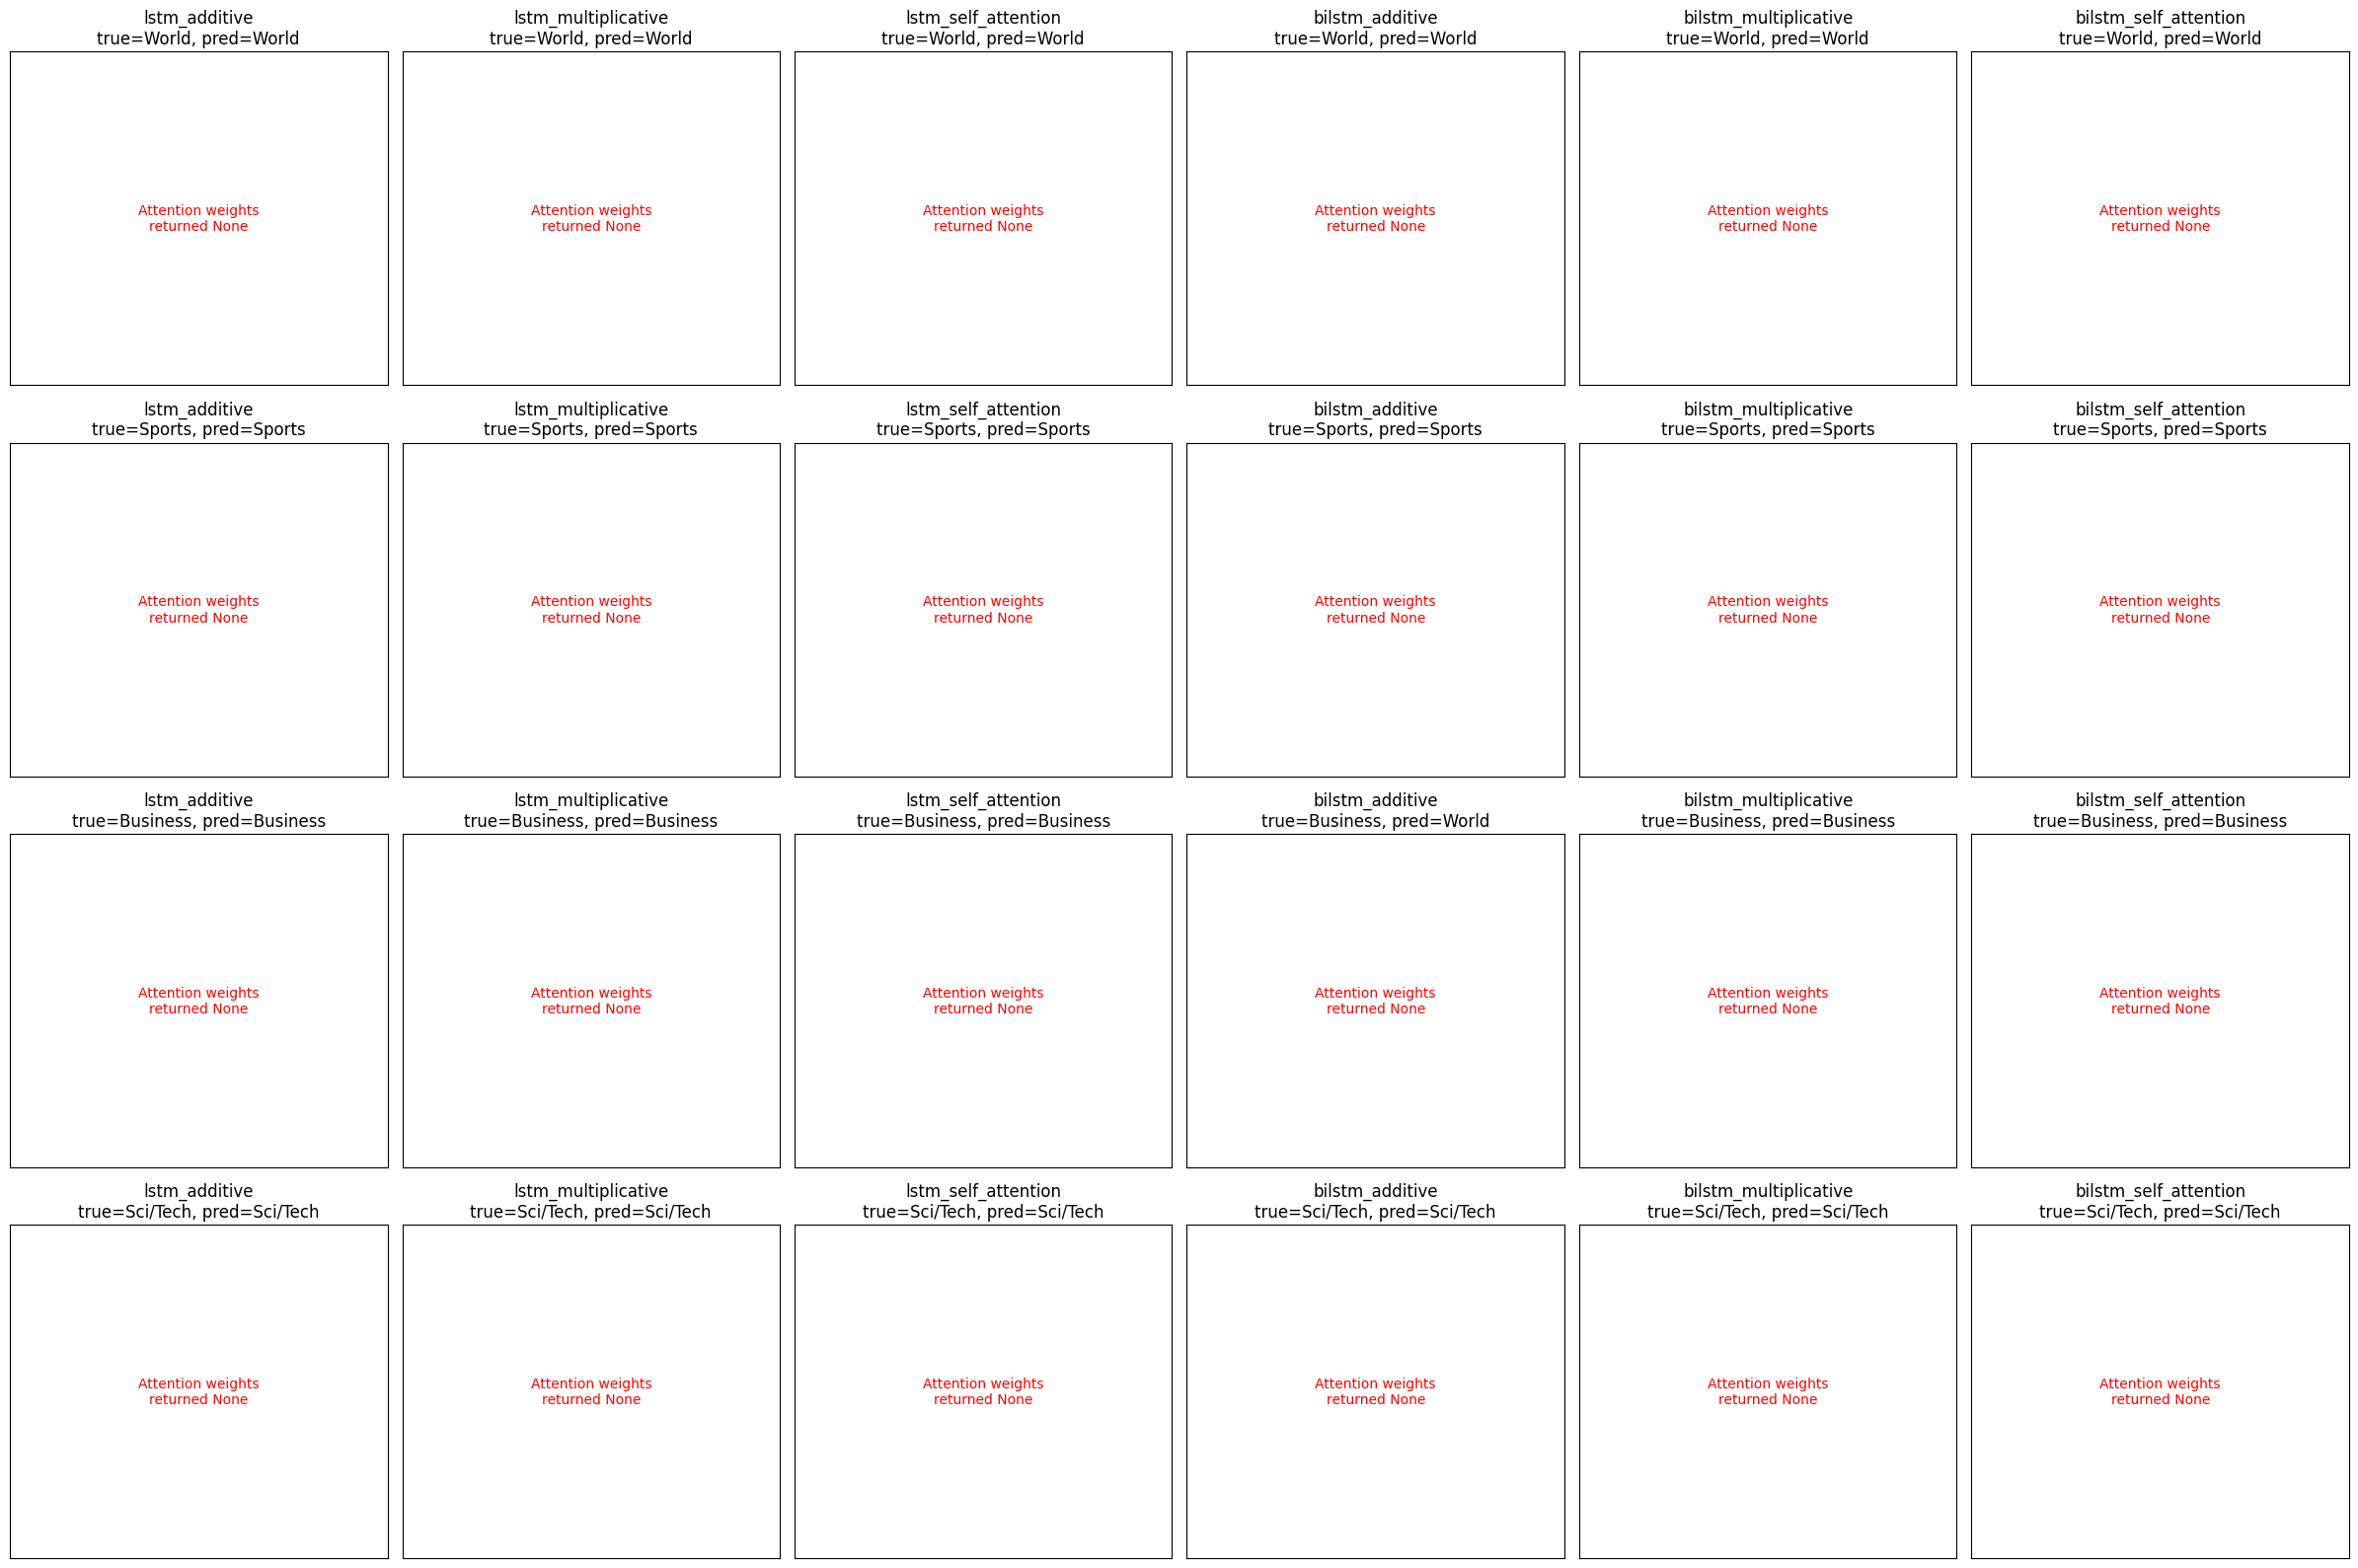

In [11]:
import matplotlib.pyplot as plt

ATTENTION_MODELS = ['lstm_additive', 'lstm_multiplicative', 'lstm_self_attention',
                    'bilstm_additive', 'bilstm_multiplicative', 'bilstm_self_attention']
if full_rows:
    fig, axes = plt.subplots(4, len(ATTENTION_MODELS), figsize=(24, 16), squeeze=False)
    for class_id in range(4):
        example_id = int(np.flatnonzero(test_y == class_id)[0])
        tokens = tokenize(test_texts[example_id])[:MAX_LEN]
        if not tokens:
            tokens = ['<UNK>']
        token_count = len(tokens)
        ids = data['x_test'][example_id:example_id + 1]
        seq_len = data['len_test'][example_id:example_id + 1]
        for col, model_name in enumerate(ATTENTION_MODELS):
            ax = axes[class_id, col]
            candidates = [r for r in full_rows if r['model'] == model_name]
            if not candidates:
                ax.axis('off')
                ax.set_title(f'{model_name}: no completed run')
                continue
            selected = min(candidates, key=lambda r: r['best_validation_loss'])
            model = LSTMTextClassifier(model_name, len(data['vocab'])).to(DEVICE)
            checkpoint = torch.load(selected['checkpoint'], map_location=DEVICE, weights_only=False)
            model.load_state_dict(checkpoint['state_dict'])
            model.eval()
            with torch.no_grad():
                logits, weights = model(ids, seq_len, return_attention=True)

            if weights is None:
                ax.text(0.5, 0.5, 'Attention weights\nreturned None',
                        ha='center', va='center', color='red', fontsize=10)
                ax.set_xticks([])
                ax.set_yticks([])
                predicted = CLASS_NAMES[int(logits.argmax(1).item())]
                ax.set_title(f'{model_name}\ntrue={CLASS_NAMES[class_id]}, pred={predicted}')
                del model
                continue

            values = weights[0].cpu().numpy()
            if values.ndim == 1:
                image = values[:token_count][None, :]
                ax.imshow(image, aspect='auto', cmap='viridis')
                ax.set_yticks([])
            else:
                image = values[:token_count, :token_count]
                ax.imshow(image, aspect='auto', cmap='viridis')
                ax.set_yticks(range(token_count))
                ax.set_yticklabels(tokens, fontsize=7)
                ax.set_ylabel('Query token')
            ax.set_xticks(range(token_count))
            ax.set_xticklabels(tokens, rotation=70, ha='right', fontsize=7)
            predicted = CLASS_NAMES[int(logits.argmax(1).item())]
            ax.set_title(f'{model_name}\ntrue={CLASS_NAMES[class_id]}, pred={predicted}')
            del model
    fig.tight_layout()
    plt.show()
else:
    print('Run the full experiment before generating attention heatmaps.')
